# Dataset structure and visual checks

This notebook only reads files under `data/raw/`. It checks five datasets, shows examples, and reports missing files without changing the raw data.

## Step 0: Import tools and set the raw-data location

The helper functions below find images recursively and locate a mask that belongs to an image.

In [1]:
import os
import glob
import random
import xml.etree.ElementTree as ET
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw

RAW_ROOT = r"D:\Infosys springboards\data\raw"
DATASET_NAMES = ["sdnet2018", "concrete_crack_cls", "rdd2022", "crack500", "cfd"]
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".jpe", ".png", ".bmp", ".tif", ".tiff")
random.seed(42)

def find_dataset_folder(dataset_name):
    if not os.path.isdir(RAW_ROOT):
        print(f"Raw data path is missing: {RAW_ROOT}")
        return None
    names = os.listdir(RAW_ROOT)
    match = next((name for name in names if name.lower() == dataset_name.lower()), None)
    if match is None:
        wanted = dataset_name.lower().replace("_", "")
        match = next((name for name in names if wanted.startswith(name.lower().replace("_", "")) or name.lower().replace("_", "").startswith(wanted)), None)
        if match:
            print(f"Using folder '{match}' for {dataset_name}.")
    if match is None:
        print(f"Dataset folder is missing: {os.path.join(RAW_ROOT, dataset_name)}")
        return None
    return os.path.join(RAW_ROOT, match)

def get_image_files(folder):
    if not folder or not os.path.isdir(folder):
        return []
    all_paths = glob.glob(os.path.join(folder, "**", "*"), recursive=True)
    return sorted(path for path in all_paths if os.path.isfile(path) and os.path.splitext(path)[1].lower() in IMAGE_EXTENSIONS)

def get_dataset_images(dataset_name, folder):
    files = get_image_files(folder)
    if dataset_name == "rdd2022":
        files = [path for path in files if "images" in [part.lower() for part in path.split(os.sep)]]
    elif dataset_name == "crack500":
        files = [path for path in files if os.path.splitext(path)[1].lower() == ".jpg" and any(part.lower() in ("traindata", "testdata", "valdata") for part in path.split(os.sep))]
    elif dataset_name == "cfd":
        files = [path for path in files if "images" in [part.lower() for part in path.split(os.sep)] and os.path.splitext(path)[1].lower() in (".jpg", ".jpeg", ".jpe")]
    return files

def find_mask_path(dataset_name, image_path, dataset_folder):
    stem = os.path.splitext(os.path.basename(image_path))[0]
    if dataset_name == "crack500":
        mask_folder = os.path.dirname(image_path)
        candidates = glob.glob(os.path.join(mask_folder, stem + "_mask.*"), recursive=True)
        candidates += glob.glob(os.path.join(mask_folder, stem + ".png"), recursive=True)
    elif dataset_name == "cfd":
        mask_folder = next((os.path.join(dataset_folder, name) for name in os.listdir(dataset_folder) if name.lower() == "masks"), None)
        candidates = glob.glob(os.path.join(mask_folder, "**", "*"), recursive=True) if mask_folder else []
        candidates = [path for path in candidates if os.path.isfile(path) and os.path.splitext(os.path.basename(path))[0].lower() == (stem + "_label").lower()]
    else:
        return None
    return next((path for path in candidates if os.path.isfile(path)), None)

def read_boxes(xml_path):
    root = ET.parse(xml_path).getroot()
    boxes = []
    for item in root.findall("object"):
        box = item.find("bndbox")
        if box is None:
            continue
        values = {key: int(float(box.findtext(key, default="0"))) for key in ("xmin", "ymin", "xmax", "ymax")}
        boxes.append((item.findtext("name", default="unknown"), values))
    return boxes

print("Raw data folder:", RAW_ROOT)
print("Datasets:", ", ".join(DATASET_NAMES))

Raw data folder: D:\Infosys springboards\data\raw
Datasets: sdnet2018, concrete_crack_cls, rdd2022, crack500, cfd


## Step 1: Check folders and print their structure

For each dataset, this lists folders and their immediate file counts, stopping at three levels below the dataset folder.

In [2]:
dataset_paths = {name: find_dataset_folder(name) for name in DATASET_NAMES}
problems = {name: [] for name in DATASET_NAMES}

for name, folder in dataset_paths.items():
    print(f"\n--- {name} ---")
    if folder is None:
        problems[name].append("Dataset folder is missing")
        continue
    for current, directories, files in os.walk(folder):
        depth = os.path.relpath(current, folder).count(os.sep)
        if os.path.relpath(current, folder) == ".":
            depth = 0
        if depth >= 3:
            directories[:] = []
        print(f"{os.path.relpath(current, folder)} | {len(directories)} folders | {len(files)} files")


--- sdnet2018 ---
. | 3 folders | 0 files
D | 2 folders | 0 files
D\CD | 0 folders | 2025 files
D\UD | 0 folders | 11595 files
P | 2 folders | 0 files
P\CP | 0 folders | 2608 files
P\UP | 0 folders | 21726 files
W | 2 folders | 0 files
W\CW | 0 folders | 3851 files
W\UW | 0 folders | 14287 files

--- concrete_crack_cls ---
. | 2 folders | 0 files
Negative | 0 folders | 20000 files
Positive | 0 folders | 20000 files

--- rdd2022 ---
. | 8 folders | 4 files
China_Drone | 1 folders | 0 files
China_Drone\train | 2 folders | 0 files
China_Drone\train\annotations | 1 folders | 0 files
China_Drone\train\annotations\xmls | 0 folders | 2401 files
China_Drone\train\images | 0 folders | 2401 files
China_MotorBike | 2 folders | 0 files
China_MotorBike\test | 1 folders | 0 files
China_MotorBike\test\images | 0 folders | 500 files
China_MotorBike\train | 2 folders | 0 files
China_MotorBike\train\annotations | 1 folders | 0 files
China_MotorBike\train\annotations\xmls | 0 folders | 1977 files
China_

## Step 2: Count images by class or folder

SDNET2018 and Concrete Crack use cracked/uncracked labels when their folders indicate them. Other datasets are grouped by their label or data folder.

In [49]:
dataset_images = {}
class_counts = {}
folder_names = {}

for name, folder in dataset_paths.items():
    dataset_images[name] = get_dataset_images(name, folder)
    class_counts[name] = Counter()
    folder_names[name] = sorted(os.listdir(folder)) if folder else []
    if name == "rdd2022" and folder:
        folder_names[name] = sorted(entry for entry in os.listdir(folder) if os.path.isdir(os.path.join(folder, entry)))
    for image_path in dataset_images[name]:
        parts = os.path.relpath(image_path, folder).split(os.sep) if folder else []
        if name == "sdnet2018":
            class_folder = os.path.basename(os.path.dirname(image_path)).upper()
            label = "cracked" if class_folder in ("CD", "CP", "CW") else "uncracked" if class_folder in ("UD", "UP", "UW") else class_folder
        elif name == "concrete_crack_cls":
            label_parts = [part.lower() for part in parts[:-1]]
            if any("uncrack" in part or "negative" in part for part in label_parts):
                label = "uncracked"
            elif any("crack" in part or "positive" in part for part in label_parts):
                label = "cracked"
            else:
                label = parts[0] if len(parts) > 1 else "unlabeled"
        elif name == "rdd2022":
            label = parts[0] if len(parts) > 1 else "unlabeled"
        elif name == "crack500":
            label = next((part for part in parts if part.lower() in ("traindata", "testdata", "valdata")), "other")
        else:
            label = next((part for part in parts if part.lower() == "images"), "other")
        class_counts[name][label] += 1

for name in DATASET_NAMES:
    print(f"\n{name}: {len(dataset_images[name])} images")
    print(dict(class_counts[name]) if class_counts[name] else "No images found")


sdnet2018: 56092 images
{'cracked': 8484, 'uncracked': 47608}

concrete_crack_cls: 40000 images
{'uncracked': 20000, 'cracked': 20000}

rdd2022: 47420 images
{'China_Drone': 2401, 'China_MotorBike': 2477, 'Czech': 3538, 'India': 9665, 'Japan': 13133, 'Norway': 10201, 'United_States': 6005}

crack500: 500 images
{'testdata': 200, 'traindata': 250, 'valdata': 50}

cfd: 118 images
{'Images': 118}


## Step 3: Show one example and print its size

The reported size is `(width, height)` in pixels. Empty or missing folders are skipped with a message.


sdnet2018:
Sample: D:\Infosys springboards\data\raw\SDNET2018\D\CD\7001-115.jpg
Image size (width, height): (256, 256)


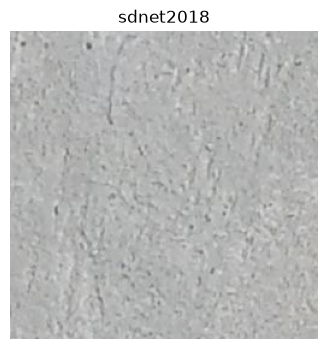


concrete_crack_cls:
Sample: D:\Infosys springboards\data\raw\concrete_crack_cls\Negative\00001.jpg
Image size (width, height): (227, 227)


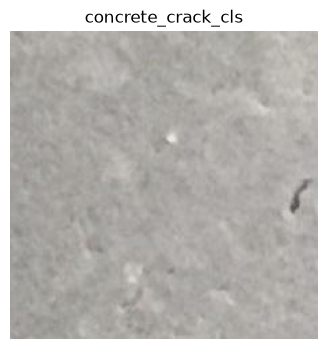


rdd2022:
Sample: D:\Infosys springboards\data\raw\rdd2022\China_Drone\train\images\China_Drone_000000.jpg
Image size (width, height): (512, 512)


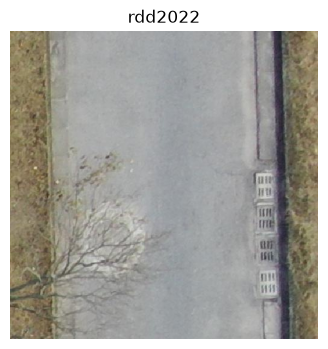


crack500:
Sample: D:\Infosys springboards\data\raw\crack500\CRACK500\testdata\testdata\20160222_080933.jpg
Image size (width, height): (1440, 2560)


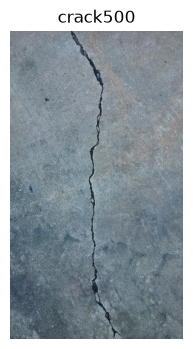


cfd:
Sample: D:\Infosys springboards\data\raw\cfd\Images\001.jpg
Image size (width, height): (480, 320)


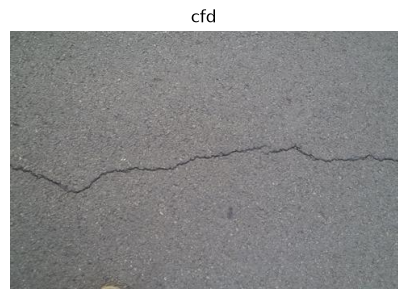

In [50]:
image_sizes = {}
for name in DATASET_NAMES:
    images = dataset_images[name]
    print(f"\n{name}:")
    if not images:
        print("No image is available to show.")
        problems[name].append("No images found")
        continue
    image_path = images[0]
    with Image.open(image_path) as image:
        image_sizes[name] = image.size
        print("Sample:", image_path)
        print("Image size (width, height):", image.size)
        plt.figure(figsize=(5, 4))
        plt.imshow(image.convert("RGB"))
        plt.title(name)
        plt.axis("off")
        plt.show()

## Step 4: Inspect XML labels and segmentation masks

RDD2022 prints damage names and box coordinates from one XML file. Crack500 and CFD print the shape and pixel values from one paired mask.

In [51]:
rdd_folder = dataset_paths["rdd2022"]
rdd_xml_files = glob.glob(os.path.join(rdd_folder, "**", "*.xml"), recursive=True) if rdd_folder else []
if rdd_xml_files:
    xml_path = rdd_xml_files[0]
    boxes = read_boxes(xml_path)
    print("RDD2022 XML:", xml_path)
    print("Damage classes and box coordinates:")
    for damage_name, coordinates in boxes:
        print(damage_name, coordinates)
else:
    print("RDD2022: no .xml annotation file was found under the dataset folder.")
    problems["rdd2022"].append("No XML annotation files found")

for name in ("crack500", "cfd"):
    folder = dataset_paths[name]
    mask_pair = next(((image_path, find_mask_path(name, image_path, folder)) for image_path in dataset_images[name] if find_mask_path(name, image_path, folder)), None)
    print(f"\n{name}:")
    if mask_pair is None:
        print("No image-mask pair was found.")
        problems[name].append("No paired mask found")
        continue
    image_path, mask_path = mask_pair
    with Image.open(mask_path) as mask:
        values = np.unique(np.array(mask))
        print("Image:", image_path)
        print("Mask:", mask_path)
        print("Mask shape:", np.array(mask).shape)
        print("Unique pixel values:", values)

RDD2022 XML: D:\Infosys springboards\data\raw\rdd2022\China_Drone\train\annotations\xmls\China_Drone_000000.xml
Damage classes and box coordinates:
D10 {'xmin': 323, 'ymin': 213, 'xmax': 390, 'ymax': 245}

crack500:
Image: D:\Infosys springboards\data\raw\crack500\CRACK500\testdata\testdata\20160222_080933.jpg
Mask: D:\Infosys springboards\data\raw\crack500\CRACK500\testdata\testdata\20160222_080933_mask.png
Mask shape: (2560, 1440)
Unique pixel values: [False  True]

cfd:
Image: D:\Infosys springboards\data\raw\cfd\Images\001.jpg
Mask: D:\Infosys springboards\data\raw\cfd\Masks\001_label.PNG
Mask shape: (320, 480)
Unique pixel values: [  0 255]


## Step 5: Plot five random images from each dataset

RDD2022 boxes are drawn when matching XML annotations exist. Crack500 and CFD masks are overlaid when a matching mask is available.


sdnet2018:


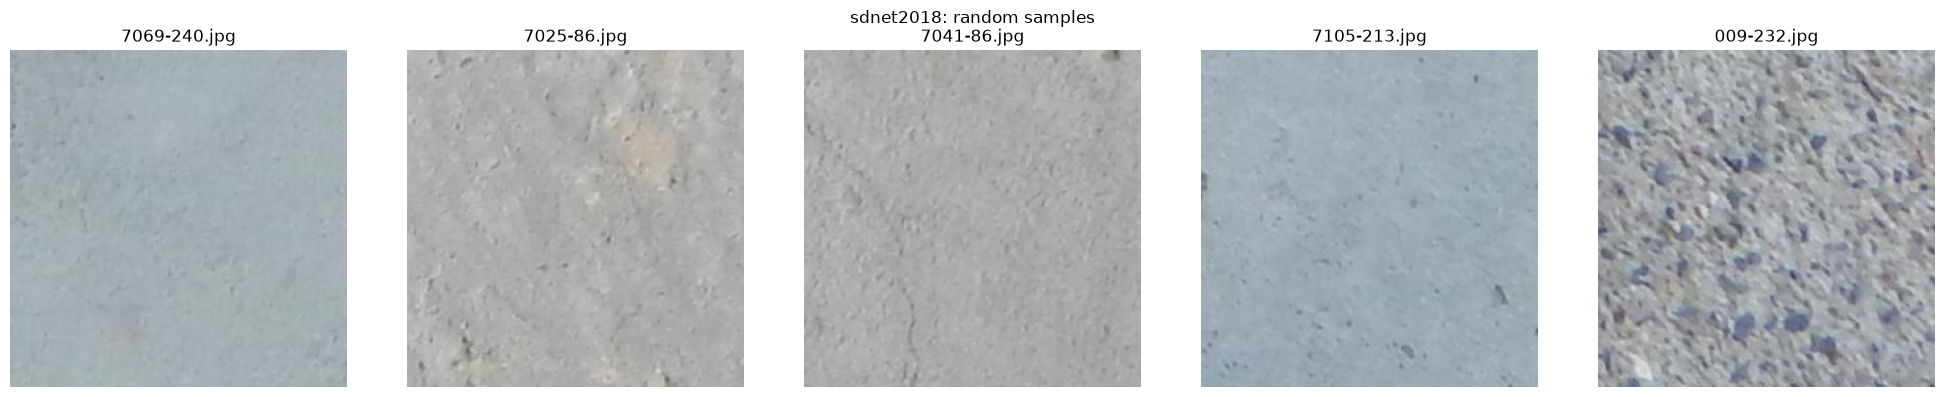


concrete_crack_cls:


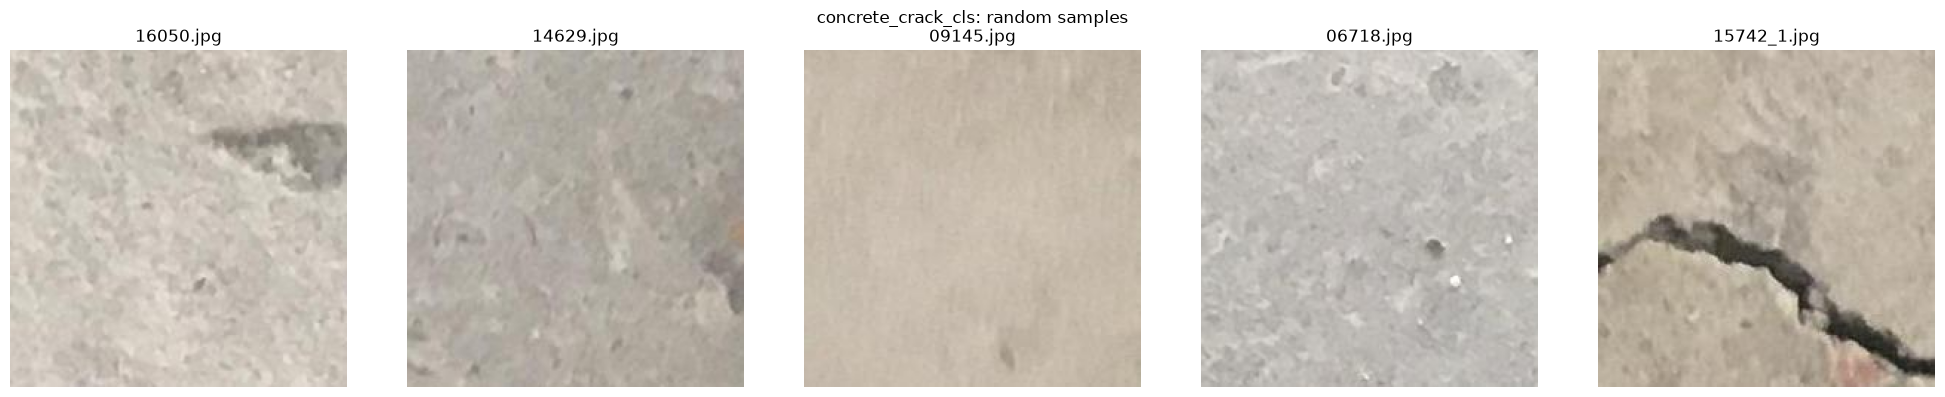


rdd2022:


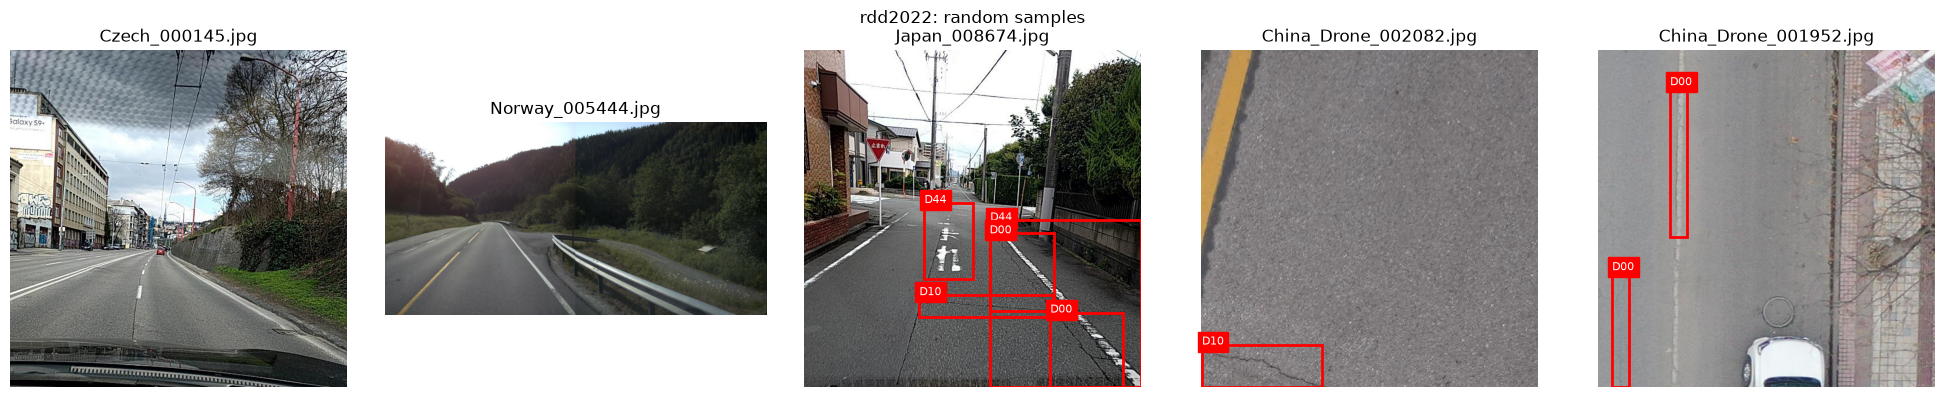


crack500:


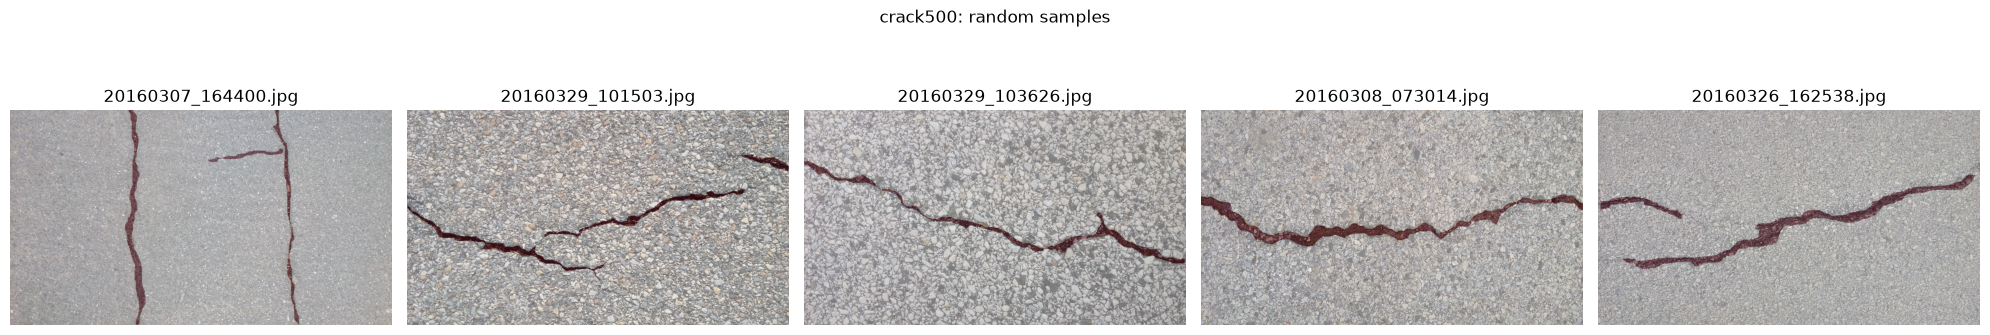


cfd:


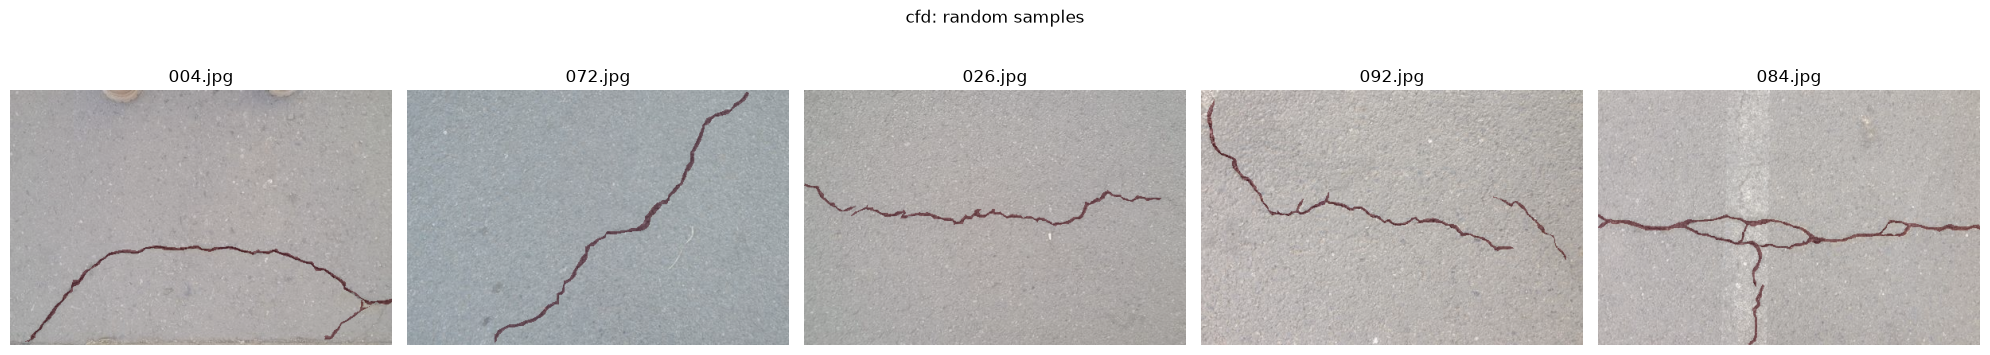

In [52]:
for name in DATASET_NAMES:
    images = dataset_images[name]
    print(f"\n{name}:")
    if not images:
        print("No images are available to plot.")
        continue
    samples = random.sample(images, min(5, len(images)))
    fig, axes = plt.subplots(1, len(samples), figsize=(4 * len(samples), 4))
    if len(samples) == 1:
        axes = [axes]
    for axis, image_path in zip(axes, samples):
        with Image.open(image_path) as image:
            axis.imshow(image.convert("RGB"))
        axis.set_title(os.path.basename(image_path))
        axis.axis("off")
        if name == "rdd2022":
            xml_path = next((path for path in glob.glob(os.path.join(dataset_paths[name], "**", "*.xml"), recursive=True) if os.path.splitext(os.path.basename(path))[0].lower() == os.path.splitext(os.path.basename(image_path))[0].lower()), None)
            if xml_path:
                for damage_name, box in read_boxes(xml_path):
                    axis.add_patch(plt.Rectangle((box["xmin"], box["ymin"]), box["xmax"] - box["xmin"], box["ymax"] - box["ymin"], fill=False, edgecolor="red", linewidth=2))
                    axis.text(box["xmin"], box["ymin"], damage_name, color="white", backgroundcolor="red", fontsize=8)
        if name in ("crack500", "cfd"):
            mask_path = find_mask_path(name, image_path, dataset_paths[name])
            if mask_path:
                with Image.open(mask_path) as mask:
                    axis.imshow(mask.convert("L"), cmap="Reds", alpha=0.35)
    fig.suptitle(f"{name}: random samples")
    plt.tight_layout()
    plt.show()

## Step 6: Compare class or folder counts

Each panel uses the counts from Step 2. A panel with no bars means no image files were found for that dataset.

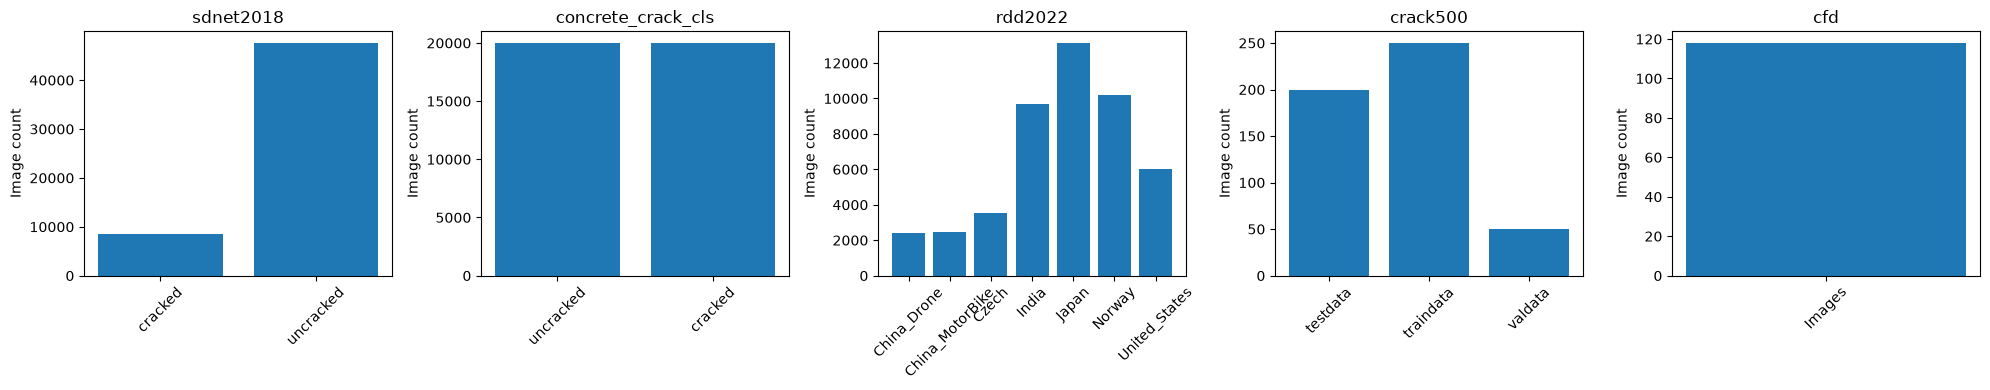

In [53]:
fig, axes = plt.subplots(1, len(DATASET_NAMES), figsize=(20, 4))
for axis, name in zip(axes, DATASET_NAMES):
    counts = class_counts[name]
    if counts:
        axis.bar(list(counts.keys()), list(counts.values()))
        axis.tick_params(axis="x", rotation=45)
    else:
        axis.text(0.5, 0.5, "No images", ha="center", va="center")
    axis.set_title(name)
    axis.set_ylabel("Image count")
plt.tight_layout()
plt.show()

## Step 7: Review a summary table

The table records the dataset folders, where labels are stored, example image size, number of source images, and any missing items detected above.

In [54]:
label_locations = {
    "sdnet2018": "Class subfolders (CD/CP/CW and UD/UP/UW)",
    "concrete_crack_cls": "Class-named folders, if present",
    "rdd2022": "Country/train folders with Pascal VOC XML bounding boxes",
    "crack500": "Paired *_mask.png files",
    "cfd": "Masks/*_label.PNG files",
}
rows = []
for name in DATASET_NAMES:
    rows.append({
        "Dataset": name,
        "Folders": ", ".join(folder_names[name]) if folder_names[name] else ("(empty)" if dataset_paths[name] else "Missing"),
        "Label stored in": label_locations[name],
        "Image size": image_sizes.get(name, "Unavailable"),
        "Number of images": len(dataset_images[name]),
        "Problems seen": "; ".join(dict.fromkeys(problems[name])) if problems[name] else "None noted",
    })
summary_table = pd.DataFrame(rows, columns=["Dataset", "Folders", "Label stored in", "Image size", "Number of images", "Problems seen"])
summary_table

,Dataset,Folders,Label stored in,Image size,Number of images,Problems seen
0,sdnet2018,"D, P, W",Class subfolders (CD/CP/CW and UD/UP/UW),"(256, 256)",56092,None noted
1,concrete_crack_cls,"Negative, Positive","Class-named folders, if present","(227, 227)",40000,None noted
2,rdd2022,"China_Drone, China_MotorBike, Czech, India, Ja...",Country/train folders with Pascal VOC XML boun...,"(512, 512)",47420,None noted
3,crack500,CRACK500,Paired *_mask.png files,"(1440, 2560)",500,None noted
4,cfd,"Images, Masks",Masks/*_label.PNG files,"(480, 320)",118,None noted
